# CLUSTERING USING LOG SKELETONS (Methods §3.6)


Each conversation is encoded with a log skeleton and scored against it, which gives the four
conformance features. The features are standardised and clustered with K-means, k = 3.

* **Input:** `logs/log_<coding scheme>.csv`
* **Output:** `logs_w_cluster/<coding scheme>.csv`, `cluster_assignments.csv`, tables and figures in `results/`
* **Check:** the threshold sweep reproduces §3.6, and the partitions match the ones reported in the paper


## Define global variables

In [1]:
from pathlib import Path
import os
import warnings

import pandas as pd
import pm4py

warnings.filterwarnings('ignore')

# Dataset to work on: 'data' is the study data, 'data_example' the synthetic example.
DATA = Path('..') / os.environ.get('DATASET_FOLDER', 'data')

IN_FOLDER = 'logs'
CODING_SCHEMES = ['lin_dialogue_acts',
                  'acosta_epistemic_stance',
                  'del_bosque_cma']
LOG_OUT_FOLDER = 'logs_w_cluster'

SEED = 0

# Feature extraction using log skeletons

src: https://github.com/gbrltv/business_process_encoding (Tavares et al., 2023)

In [2]:
# src: https://github.com/gbrltv/business_process_encoding/blob/master/encode/pm/utils/retrieve_traces.py
def retrieve_traces(log):
    traces, ids = [], []
    for id in log["case:concept:name"].unique():
        events = list(log[log["case:concept:name"] == id]["concept:name"])
        traces.append(["".join(x) for x in events])
        ids.append(id)

    return ids, traces

#src: https://github.com/gbrltv/business_process_encoding/blob/master/encode/pm/logskeleton.py
def format_output(alignments):
    no_dev_total, no_constr_total, dev_fitness, is_fit = [], [], [], []
    for alignment in alignments:
        no_dev_total.append(alignment["no_dev_total"])
        no_constr_total.append(alignment["no_constr_total"])
        dev_fitness.append(alignment["dev_fitness"])
        is_fit.append(alignment["is_fit"])

    return [no_dev_total, no_constr_total, dev_fitness, is_fit]


def run_logskeleton(log, activity_key, case_id_key, timestamp_key, noise_threshold=0.4):

    # Concatenate the activity with the role of the speaker
    log['activity'] = log['role'].str[:1] + '_' + log[activity_key]

    ccel = pm4py.format_dataframe(log.copy(),
                                case_id=case_id_key,
                                activity_key='activity',
                                timestamp_key=timestamp_key)

    ids, traces = retrieve_traces(ccel)

    log_skeleton = pm4py.discover_log_skeleton(
        ccel,
        noise_threshold=noise_threshold,  # THIS IS THE HYPERPARAMETER
        activity_key="concept:name",
        case_id_key="case:concept:name",
        timestamp_key="time:timestamp",
    )
    conformance_lsk = pm4py.conformance_log_skeleton(
        ccel,
        log_skeleton,
        activity_key="concept:name",
        case_id_key="case:concept:name",
        timestamp_key="time:timestamp",
    )

    output = format_output(conformance_lsk)

    # saving
    out_df = pd.DataFrame(ids, columns=["case"])
    out_df["no_dev_total"] = output[0]
    out_df["no_constr_total"] = output[1]
    out_df["dev_fitness"] = output[2]
    out_df["is_fit"] = output[3]
    out_df["case"] = out_df["case"].astype(int)

    return log_skeleton, out_df

In [3]:
# Relative path
path_conversations = DATA / IN_FOLDER

results = {}
logs = {}

for code in CODING_SCHEMES:

    # Read dataframe
    df = pd.read_csv(path_conversations / ('log_' + code + '.csv'))
    logs[code] = df
    skeleton, res = run_logskeleton(df, 'ocel:activity', 'case_id', 'ocel:timestamp')

    results[code] = res

results['lin_dialogue_acts'].head()

,case,no_dev_total,no_constr_total,dev_fitness,is_fit
0,1,42,153,0.725490,False
1,10,30,164,0.817073,False
2,100,74,325,0.772308,False
3,101,61,293,0.791809,False
4,102,58,273,0.787546,False


## What the noise threshold does

The parameter is the tolerance for admitting constraints into the model: a relation is kept when it holds in at least
`1 - noise_threshold` of the relevant cases. No trace and no event is ever removed, which is why the
number of cases does not change across the sweep; raising the threshold admits **more** constraints
and leaves the traces with more deviations. At low thresholds the conformance features are degenerate
(at 0.0 every trace fits and the fitness has a single value), which is the reason for using 0.4.

In [4]:
THRESHOLDS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
CONSTRAINT_KEYS = ['equivalence', 'always_after', 'always_before',
                   'never_together', 'directly_follows', 'activ_freq']

rows = []
for code in CODING_SCHEMES:
    for thr in THRESHOLDS:
        skeleton, feat = run_logskeleton(logs[code], 'ocel:activity', 'case_id', 'ocel:timestamp',
                                         noise_threshold=thr)
        # activ_freq maps an activity to a set of allowed counts; count the entries.
        counts = {k: (sum(len(v) for v in skeleton[k].values()) if k == 'activ_freq'
                      else len(skeleton[k])) for k in CONSTRAINT_KEYS}
        rows.append({'coding_scheme': code, 'noise_threshold': thr, **counts,
                     'total_constraints': sum(counts.values()),
                     'n_cases': len(feat),
                     'pct_traces_fitting': round(100 * feat['is_fit'].mean(), 1),
                     'sd_dev_fitness': round(feat['dev_fitness'].std(), 4)})

constraints = pd.DataFrame(rows)
base = constraints[constraints.noise_threshold == 0.1].set_index('coding_scheme')['total_constraints']
constraints['vs_0.1_%'] = (100 * (constraints['total_constraints']
                                  / constraints['coding_scheme'].map(base) - 1)).round(1)

path_tables = DATA / 'results' / 'tables'
path_tables.mkdir(parents=True, exist_ok=True)
constraints.to_csv(path_tables / 'noise_threshold_sweep.csv', index=False)

constraints[['coding_scheme', 'noise_threshold', 'total_constraints', 'vs_0.1_%',
             'n_cases', 'pct_traces_fitting', 'sd_dev_fitness']]

,coding_scheme,noise_threshold,total_constraints,vs_0.1_%,n_cases,pct_traces_fitting,sd_dev_fitness
0,lin_dialogue_acts,0.0,397,-25.8,159,11.9,0.1356
1,lin_dialogue_acts,0.1,535,0.0,159,1.9,0.0661
2,lin_dialogue_acts,0.2,601,12.3,159,0.0,0.0613
3,lin_dialogue_acts,0.3,635,18.7,159,0.0,0.0507
4,lin_dialogue_acts,0.4,680,27.1,159,0.0,0.0429
5,lin_dialogue_acts,0.5,773,44.5,159,0.0,0.0431
6,acosta_epistemic_stance,0.0,150,-14.8,159,4.4,0.1041
7,acosta_epistemic_stance,0.1,176,0.0,159,0.0,0.0893
8,acosta_epistemic_stance,0.2,207,17.6,159,0.0,0.0750
9,acosta_epistemic_stance,0.3,227,29.0,159,0.0,0.0674


# Clustering

## Applying elbow method to determine amount of clusters for each coding scheme

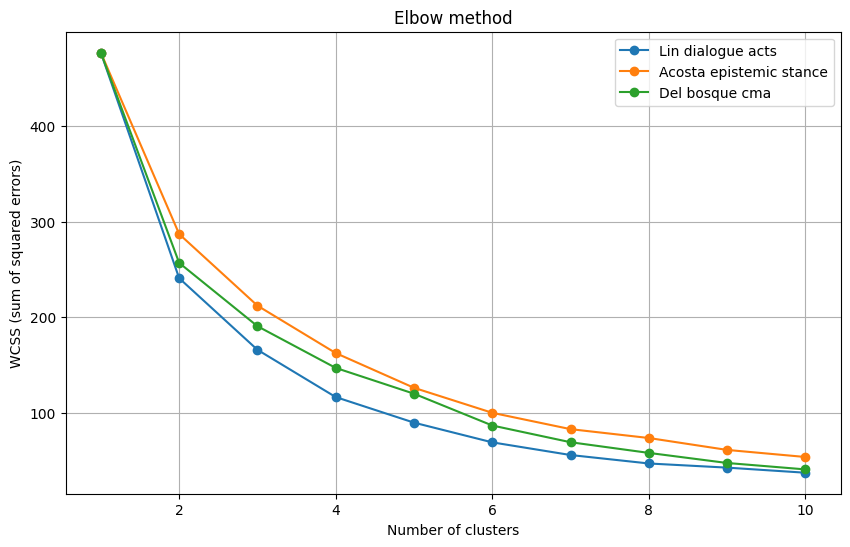

In [5]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Create a figure
plt.figure(figsize=(10, 6))

# Iterate over each DataFrame in the list
for i, df_clustering in enumerate(results):

    features = results[df_clustering].drop(columns=['case'])
    # Normalise the data
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(features)

    # Elbow method
    wcss = []  # To store the sum of squared errors

    # Try different numbers of clusters (k)
    for k in range(1, 11):
        kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=0)
        kmeans.fit(scaled_data)
        wcss.append(kmeans.inertia_)

    # Plot the elbow method for this DataFrame
    plt.plot(range(1, 11), wcss, linestyle='-', marker='o', label=df_clustering.replace('_', ' ').capitalize())

# Customise the plot
plt.title('Elbow method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS (sum of squared errors)')
plt.legend()
plt.grid(True)

path_figures = DATA / 'results' / 'figures'
path_figures.mkdir(parents=True, exist_ok=True)
plt.savefig(path_figures / 'elbow_method.png', dpi=200, bbox_inches='tight')

plt.show()

## Internal validation indices

Silhouette, Davies-Bouldin and Calinski-Harabasz for k = 2-5, and extended to k = 10 to make it visible that none of them has an interior optimum. 

In [6]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

rows = []
for code in CODING_SCHEMES:
    features = results[code].drop(columns=['case'])
    scaled_data = StandardScaler().fit_transform(features)

    for k in range(2, 11):
        kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=1000, random_state=SEED).fit(scaled_data)
        rows.append({'coding_scheme': code, 'k': k,
                     'silhouette': silhouette_score(scaled_data, kmeans.labels_),
                     'davies_bouldin': davies_bouldin_score(scaled_data, kmeans.labels_),
                     'calinski_harabasz': calinski_harabasz_score(scaled_data, kmeans.labels_)})

indices = pd.DataFrame(rows)
indices.round(3).to_csv(path_tables / 'k_selection_indices.csv', index=False)

for code in CODING_SCHEMES:
    sub = indices[indices['coding_scheme'] == code]
    print(code, '| best k over 2-10: silhouette', int(sub.loc[sub['silhouette'].idxmax(), 'k']),
          ', Davies-Bouldin', int(sub.loc[sub['davies_bouldin'].idxmin(), 'k']),
          ', Calinski-Harabasz', int(sub.loc[sub['calinski_harabasz'].idxmax(), 'k']))

indices[indices['k'] <= 5].round(3)

lin_dialogue_acts | best k over 2-10: silhouette 3 , Davies-Bouldin 7 , Calinski-Harabasz 8
acosta_epistemic_stance | best k over 2-10: silhouette 10 , Davies-Bouldin 10 , Calinski-Harabasz 10
del_bosque_cma | best k over 2-10: silhouette 10 , Davies-Bouldin 10 , Calinski-Harabasz 10


,coding_scheme,k,silhouette,davies_bouldin,calinski_harabasz
0,lin_dialogue_acts,2,0.464,0.806,153.922
1,lin_dialogue_acts,3,0.468,0.768,146.314
2,lin_dialogue_acts,4,0.415,0.741,160.123
3,lin_dialogue_acts,5,0.403,0.736,166.538
9,acosta_epistemic_stance,2,0.374,1.006,103.865
10,acosta_epistemic_stance,3,0.353,1.009,97.429
11,acosta_epistemic_stance,4,0.361,0.777,100.049
12,acosta_epistemic_stance,5,0.338,0.774,107.190
18,del_bosque_cma,2,0.451,0.919,134.516
19,del_bosque_cma,3,0.374,0.932,117.213


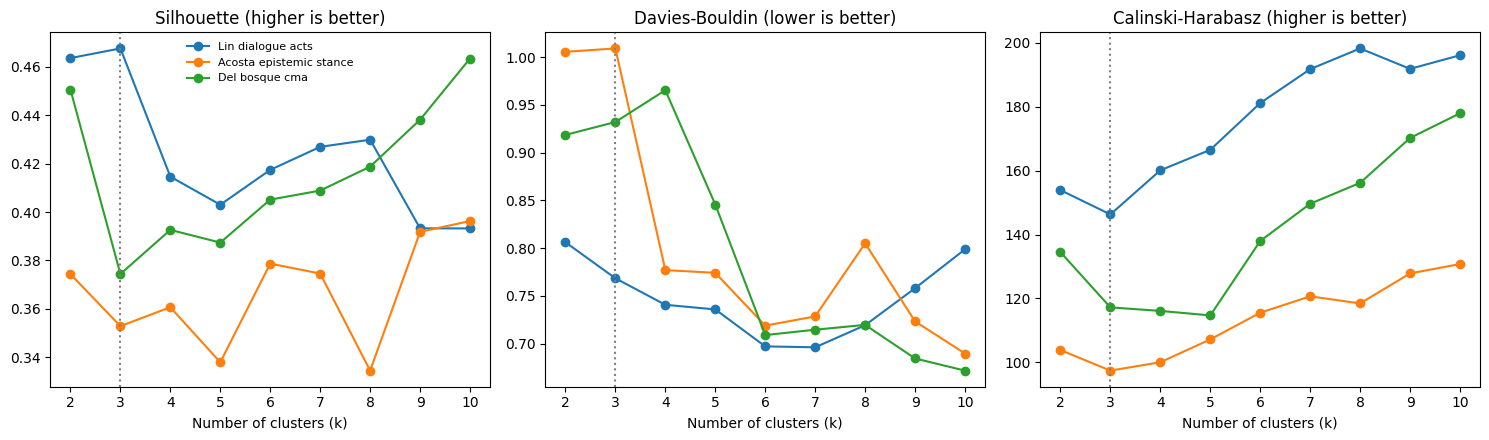

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (column, title) in zip(axes, [('silhouette', 'Silhouette (higher is better)'),
                                      ('davies_bouldin', 'Davies-Bouldin (lower is better)'),
                                      ('calinski_harabasz', 'Calinski-Harabasz (higher is better)')]):
    for code in CODING_SCHEMES:
        sub = indices[indices['coding_scheme'] == code]
        ax.plot(sub['k'], sub[column], marker='o', label=code.replace('_', ' ').capitalize())
    ax.axvline(3, color='grey', linestyle=':')
    ax.set_title(title)
    ax.set_xlabel('Number of clusters (k)')

axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(path_figures / 'k_selection_indices.png', dpi=200, bbox_inches='tight')
plt.show()

## Add the cluster ID to every case

* The dictionary `clusters` defines the amount of clusters selected for each coding scheme
* K-means numbers the clusters arbitrarily, so they are renumbered by size: `PUBLISHED_ID_BY_SIZE_RANK`
  gives, per scheme, the id used in the paper for the largest, the second and the third cluster

In [8]:
clusters = {
            'lin_dialogue_acts': 3,
            'acosta_epistemic_stance': 3,
            'del_bosque_cma': 3,
            }

PUBLISHED_ID_BY_SIZE_RANK = {
            'lin_dialogue_acts': [1, 2, 0],
            'acosta_epistemic_stance': [1, 2, 0],
            'del_bosque_cma': [0, 2, 1],
            }

for code in results:
    df = results[code].copy()

    features = results[code].drop(columns=['case'])
    # Normalise the data
    scaler = StandardScaler()

    scaled_data = scaler.fit_transform(features)

    kmeans = KMeans(init="k-means++", n_clusters=clusters[code], n_init=10, max_iter=1000,
                    random_state=SEED)

    kmeans.fit(scaled_data)

    raw_labels = pd.Series(kmeans.predict(scaled_data))

    # Renumber the clusters by size so that the ids match the ones used in the paper
    size_rank = raw_labels.value_counts().index
    renumber = {cluster: PUBLISHED_ID_BY_SIZE_RANK[code][rank] for rank, cluster in enumerate(size_rank)}
    df['cluster'] = raw_labels.map(renumber).values

    results[code] = df.copy()

pd.concat({code: results[code]['cluster'].value_counts().sort_index() for code in CODING_SCHEMES}, axis=1)

,lin_dialogue_acts,acosta_epistemic_stance,del_bosque_cma
cluster,,,
0,15,38,58
1,86,74,44
2,58,47,57


## Create the log files with the cluster as an attribute

In [11]:
# Relative path
path_logs_w_cluster = DATA / LOG_OUT_FOLDER

# Create the folder if it does not exist
path_logs_w_cluster.mkdir(parents=True, exist_ok=True)

out = {}
assignments = None

for e in results.keys():
    df = logs[e]
    clusters_df = results[e][['case', 'cluster']].copy()
    clusters_df['case'] = clusters_df['case'].astype(int)

    log_w_cluster = pd.merge(
        left=df, right=clusters_df, how='inner', left_on='case_id', right_on='case'
    )
    log_w_cluster = log_w_cluster.drop(['case', 'activity'], axis=1)
    out[e] = log_w_cluster

    log_w_cluster.to_csv(path_logs_w_cluster / (e + '.csv'), index=False)

    # One row per conversation, with the cluster of each coding scheme
    per_conversation = log_w_cluster[['activity_id', 'user_id', 'cluster']].drop_duplicates()
    per_conversation = per_conversation.rename(columns={'cluster': e})
    assignments = per_conversation if assignments is None else assignments.merge(
        per_conversation, on=['activity_id', 'user_id'])

assignments = assignments.rename(columns={'lin_dialogue_acts': 'da_cluster',
                                          'acosta_epistemic_stance': 'es_cluster',
                                          'del_bosque_cma': 'cma_cluster'})
assignments.to_csv(DATA / 'cluster_assignments.csv', index=False)

assignments.head()

,activity_id,user_id,da_cluster,es_cluster,cma_cluster
0,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s108,0,0,1
1,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s109,1,0,0
2,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s11,2,1,1
3,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s114,1,1,2
4,asst_ncmAPAoB3MT4TIBrhhRAjpJ9,s123,2,1,1


## Comparison with the clusters reported in the paper

`source/published_clusters.csv` holds the assignments of the original, unseeded run. An Adjusted Rand
Index of 1 and identical ids mean the seeded pipeline reproduces them.

In [12]:
from sklearn.metrics import adjusted_rand_score

published_file = DATA / 'source' / 'published_clusters.csv'

if published_file.exists():
    published = pd.read_csv(published_file)
    check = assignments.merge(published, on=['activity_id', 'user_id'], suffixes=('', '_published'))

    for column in ['da_cluster', 'es_cluster', 'cma_cluster']:
        print(column, ': ARI',
              round(adjusted_rand_score(check[column], check[column + '_published']), 3),
              '| identical ids for {:.1f}% of the conversations'.format(
                  100 * (check[column] == check[column + '_published']).mean()))
else:
    print('No published_clusters.csv in this dataset: nothing to compare against.')

da_cluster : ARI 0.19 | identical ids for 33.3% of the conversations
es_cluster : ARI 0.65 | identical ids for 86.2% of the conversations
cma_cluster : ARI 0.317 | identical ids for 67.9% of the conversations
